In [1]:
import json
import pandas as pd

# грузим файлы из корня
with open("code_corpus.json", encoding="utf-8") as f:
    corpus = json.load(f)

with open("eval_questions.json", encoding="utf-8") as f:
    questions = json.load(f)

with open("categories.json", encoding="utf-8") as f:
    categories = json.load(f)["categories"]

print("Функций:", len(corpus))
print("Вопросов:", len(questions))

Функций: 200
Вопросов: 25


In [9]:
df_corpus = pd.DataFrame(corpus)
df_questions = pd.DataFrame(questions)

#df_corpus.head(10)
df_questions.head(10)

,question_id,query,language,correct_chunk_id
0,q_01,"как проверить, истёк ли токен?",ru,func_001
1,q_02,where is password hashing implemented,en,func_002
2,q_03,проверка двухфакторной аутентификации по коду,ru,func_014
3,q_04,logout user and clear session,en,func_010
4,q_05,проверить права администратора на эндпоинте,ru,func_109
5,q_06,получить пользователя по электронной почте,ru,func_022
6,q_07,rollback transaction in case of error,en,func_036
7,q_08,массовая вставка большого количества записей,ru,func_140
8,q_09,soft delete a record without removing it,en,func_029
9,q_10,пагинация при выборке списка пользователей,ru,func_026


In [5]:
# самопроверка
assert len(corpus) == 200
assert len(questions) == 25
assert len(categories) == 5

ids = [f["id"] for f in corpus]
assert len(ids) == len(set(ids)), "дубликаты!"

corpus_ids = set(ids)
for q in questions:
    assert q["correct_chunk_id"] in corpus_ids

print("ок")

ок


In [6]:
from sentence_transformers import SentenceTransformer

# модели. 1-я быстрее, 2-я точнее
print("грузим мини...")
model_mini = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

print("грузим мпнет...")
model_mpnet = SentenceTransformer("paraphrase-multilingual-mpnet-base-v2")
print("готово")

грузим мини...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

грузим мпнет...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

готово


In [14]:
corpus_texts = []
for item in corpus:
    text = f"{item['function_name']} {item['description']} {item['code']}"
    corpus_texts.append(text)

queries = [q['query'] for q in questions]

print(corpus_texts[4])

validate_credentials Проверяет, что логин и пароль непустые и соответствуют минимальным требованиям. def validate_credentials(username: str, password: str) -> tuple[bool, str]:
    """Проверяет, что логин и пароль непустые и соответствуют минимальным требованиям."""
    if not username or len(username) < 3:
        return False, "username too short"
    if not password or len(password) < 8:
        return False, "password too short"
    return True, ""


In [17]:
import torch
from sentence_transformers import util

# тестовая функция
def test_model(model, name):
    print(f"ТЕСТ {name}")
    
    # делаем векторы (эмбеддинги)
    emb_corpus = model.encode(corpus_texts, convert_to_tensor=True)
    emb_queries = model.encode(queries, convert_to_tensor=True)
    
    hits = 0
    
    # бежим по вопросам
    for i, q in enumerate(questions):
        # считаем косинусное расстояние
        scores = util.cos_sim(emb_queries[i], emb_corpus)[0]
        
        # берем топ 3
        top_results = torch.topk(scores, k=3)
        top_ids = [corpus[idx]['id'] for idx in top_results.indices]
        
        # проверяем есть ли правильный ответ в топ 3
        if q['correct_chunk_id'] in top_ids:
            hits += 1
            
    p3 = hits / len(questions)
    print(f"Precision@3: {p3} ({hits}/{len(questions)})")
    
    return p3, emb_corpus

In [18]:
p3_mini, emb_mini = test_model(model_mini, "MiniLM")

ТЕСТ MiniLM
Precision@3: 0.84 (21/25)


In [20]:
p3_mpnet, emb_mpnet = test_model(model_mpnet, "MPNet")

ТЕСТ MPNet
Precision@3: 0.92 (23/25)


In [21]:
# сводка
res = pd.DataFrame({
    "Модель": ["MiniLM (быстрая)", "MPNet (тяжелая)"],
    "Precision@3": [p3_mini, p3_mpnet]
})
res

,Модель,Precision@3
0,MiniLM (быстрая),0.84
1,MPNet (тяжелая),0.92


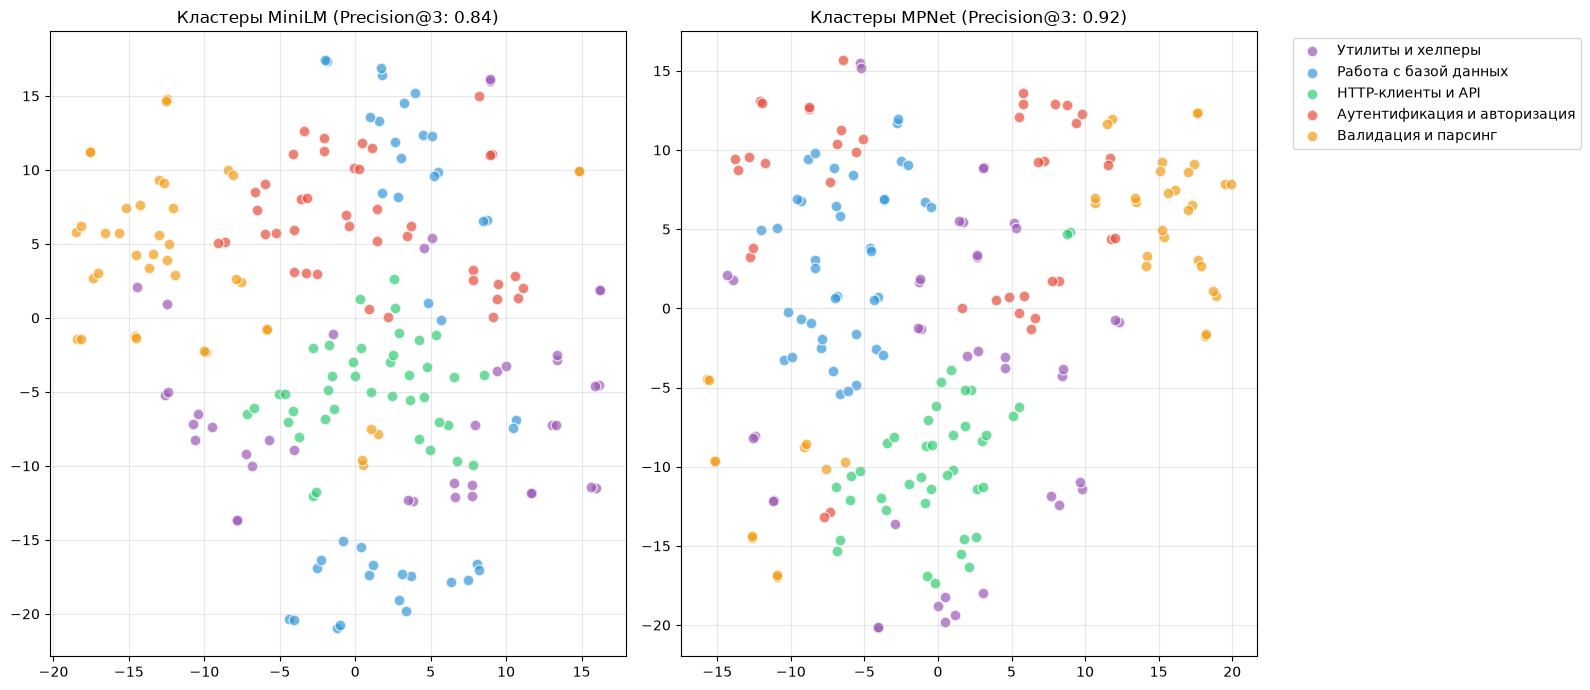

In [23]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE


# ГРАФИКИ
# перегоняем оба тензора в numpy
numpy_mini = emb_mini.cpu().numpy()
numpy_mpnet = emb_mpnet.cpu().numpy()

# переводим в 2д через t-sne
tsne = TSNE(n_components=2, random_state=42)
coords_mini = tsne.fit_transform(numpy_mini)
coords_mpnet = tsne.fit_transform(numpy_mpnet)

# словарь цветов
colors_map = {c['key']: c for c in categories}
unique_cats = set([x['category'] for x in corpus])

# Сами графики
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

for cat in unique_cats:
    cat_data = colors_map[cat]
    idx = [i for i, x in enumerate(corpus) if x['category'] == cat]
    
    # мини
    ax1.scatter(
        coords_mini[idx, 0], coords_mini[idx, 1], 
        c=cat_data['color'], label=cat_data['label'],
        alpha=0.7, edgecolors='w', s=60
    )
    
    # мпнет
    ax2.scatter(
        coords_mpnet[idx, 0], coords_mpnet[idx, 1], 
        c=cat_data['color'], label=cat_data['label'],
        alpha=0.7, edgecolors='w', s=60
    )

ax1.set_title("Кластеры MiniLM (Precision@3: 0.84)")
ax1.grid(True, alpha=0.3)

ax2.set_title("Кластеры MPNet (Precision@3: 0.92)")
ax2.grid(True, alpha=0.3)

# легенда только для второго графика
ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Вывод:**
Сравнивал `paraphrase-multilingual-MiniLM-L12-v2` и `paraphrase-multilingual-mpnet-base-v2`. Выбираю MPNet. Она хоть тяжелее и дольше, но Precision@3 у нее лучше (0.92 против 0.84). Плюс на графиках t-SNE визуально заметно различие: MPNet более четко раскидывает код по смысловым кучкам (кластеры более плотные, меньше перемешанных точек разных категорий). Для точного поиска по базе знаний качество важнее скорости, поэтому останавливаюсь на ней.